In [ ]:
#1. Importação das bibliotecas
# Biblioteca para manipulação de dados
import pandas as pd
# Biblioteca para criação de gráficos
import matplotlib.pyplot as plt

# Algoritmo de Árvore de Decisão e sua visualização
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Algoritmo Random Forest
from sklearn.ensemble import RandomForestClassifier

# Função para dividir os dados em treinamento e teste
from sklearn.model_selection import train_test_split

# Funções para avaliar os modelos de classificação
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
#2. Criação do conjunto de dados
# Criando um conjunto de dados de 20 máquinas industriais
dados = {
    # Quantidade de peças produzidas
    "producao": [
        1000, 500, 1200, 400, 1100,
        300, 950, 450, 1050, 550,
        1300, 600, 1150, 350, 900,
        650, 1250, 480, 1080, 520],
    # Consumo de energia em kWh
    "energia": [
        200, 250, 240, 300, 220,
        280, 210, 270, 230, 310,
        260, 290, 235, 260, 195,
        320, 250, 295, 225, 275
    ],
    # Classificação conhecida de cada máquina
    # 1 = Eficiente
    # 0 = Ineficiente
    "eficiente": [
        1, 0, 1, 0, 1,
        0, 1, 0, 1, 0,
        1, 0, 1, 0, 1,
        0, 1, 0, 1, 0
    ]
}
# Transforma o dicionário em um DataFrame
df = pd.DataFrame(dados)
print(df)#Exibe os dados


In [ ]:
df.head()

In [ ]:
#3. Separação das variáveis X e y
# X representa as características utilizadas pelo modelo
# São chamadas de variáveis independentes ou preditoras
X = df[["producao", "energia"]]

# y representa a classificação que queremos prever
# É chamada de variável-alvo
y = df["eficiente"]

In [ ]:
#4. Divisão em treinamento e teste
# Divide o conjunto de dados em treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,                # Variáveis de entrada
    y,                # Classificações conhecidas
    test_size=0.20,   # Reserva 20% dos dados para teste
    random_state=42,  # Mantém o mesmo sorteio em cada execução
    stratify=y        # Preserva a proporção das classes
)

# Exibe a quantidade de registros de cada conjunto
print("Treinamento:", len(X_treino))
print("Teste:", len(X_teste))

Treinamento: 16
Teste: 4


In [ ]:
#5. Treinamento da Árvore de Decisão
# Cria o algoritmo de classificação
modelo_arvore = DecisionTreeClassifier(
    random_state=42
)

# Treina a árvore utilizando somente os dados de treinamento
modelo_arvore.fit(X_treino, y_treino)

# Utiliza a árvore treinada para classificar os dados de teste
previsao_arvore = modelo_arvore.predict(X_teste)

# Exibe as classificações reais e as previstas
print("Valores reais:", y_teste.values)
print("Previsões:", previsao_arvore)

Valores reais: [0 0 1 1]
Previsões: [0 0 1 1]


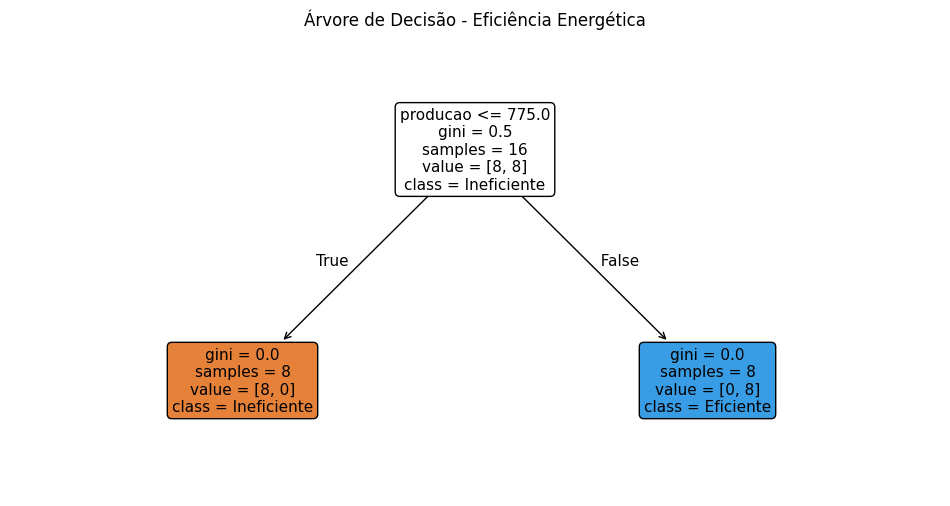

In [ ]:
#6. Visualização da Árvore de Decisão
# Define o tamanho da figura
plt.figure(figsize=(12, 6))

# Desenha a árvore treinada
plot_tree(
    modelo_arvore,

    # Nomes das variáveis de entrada
    feature_names=["producao", "energia"],

    # Nomes das classes de saída (0 e 1)
    class_names=["Ineficiente", "Eficiente"],

    # Preenche os nós com cores de acordo com as classes
    filled=True,

    # Deixa as caixas com bordas arredondadas
    rounded=True,

    # Define o tamanho das letras
    fontsize=11
)

# Adiciona um título
plt.title("Árvore de Decisão - Eficiência Energética")

# Exibe o gráfico
plt.show()

In [ ]:
#7. Treinamento do Random Forest
# Cria um modelo Random Forest com 100 árvores de decisão
modelo_rf = RandomForestClassifier(
    n_estimators=100,  # Número de árvores da floresta
    random_state=42   # Garante a reprodução dos resultados
)

# Treina o Random Forest com os dados de treinamento
modelo_rf.fit(X_treino, y_treino)

# Classifica as máquinas do conjunto de teste
previsao_rf = modelo_rf.predict(X_teste)

# Exibe os resultados previstos
print("Previsões Random Forest:", previsao_rf)

Previsões Random Forest: [0 0 1 1]


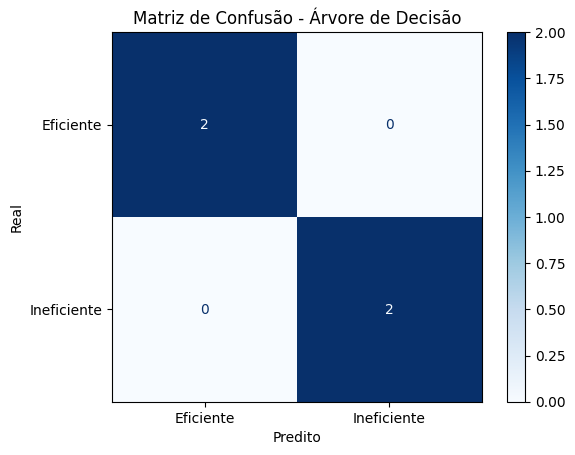

In [ ]:
#8. Matriz de confusão
# Calcula a matriz de confusão da Árvore de Decisão
matriz_arvore = confusion_matrix(
    y_teste,           # Classificações reais
    previsao_arvore,   # Classificações previstas
    labels=[0, 1]      # Ordem das classes
)

# Prepara a visualização da matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_arvore,
    display_labels=["Eficiente", "Ineficiente"]
)

# Desenha a matriz utilizando a escala de cores azul
disp.plot(cmap="Blues", values_format="d")

# Adiciona o título do gráfico
plt.title("Matriz de Confusão - Árvore de Decisão")
plt.xlabel('Predito')
plt.ylabel('Real')

# Exibe o resultado
plt.show()

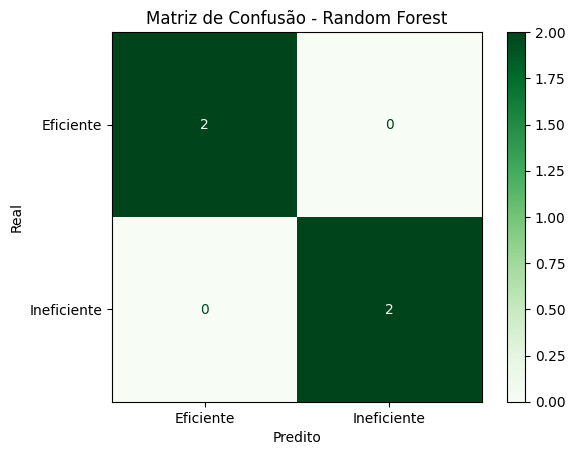

In [ ]:
#9. Métricas de avaliação
# Calcula a matriz de confusão do Random Forest
matriz_rf = confusion_matrix(
    y_teste,     # Classificações reais
    previsao_rf, # Classificações previstas pelo Random Forest
    labels=[0, 1]
)

# Cria a visualização da matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["Eficiente", "Ineficiente"]
)

# Exibe a matriz em verde
disp.plot(cmap="Greens", values_format="d")

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()

In [ ]:
# Calcula as métricas da Árvore de Decisão

# Acurácia: proporção total de classificações corretas
acuracia = accuracy_score(y_teste, previsao_arvore)

# Precisão: entre as máquinas previstas como eficientes,
# quantas realmente eram eficientes?
precisao = precision_score(
    y_teste, previsao_arvore, zero_division=0
)

# Recall: entre todas as máquinas realmente eficientes,
# quantas foram identificadas corretamente?
recall = recall_score(
    y_teste, previsao_arvore, zero_division=0
)

# F1-score: média harmônica entre precisão e recall
f1 = f1_score(
    y_teste, previsao_arvore, zero_division=0
)

# Exibe os resultados das métricas
print(f"Acurácia: {acuracia:.2f}")
print(f"Precisão: {precisao:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-score: {f1:.2f}")

Acurácia: 1.00
Precisão: 1.00
Recall: 1.00
F1-score: 1.00


In [ ]:
#10. Comparação dos dois modelos
# Organiza os modelos treinados em um dicionário
modelos = {
    "Árvore de Decisão": modelo_arvore,
    "Random Forest": modelo_rf
}

# Lista para armazenar os resultados das avaliações
resultados = []

# Percorre os dois modelos
for nome, modelo in modelos.items():

    # Realiza previsões com os dados de teste
    previsao = modelo.predict(X_teste)

    # Calcula as métricas e adiciona à lista
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsao),
        "Precisão": precision_score(
            y_teste, previsao, zero_division=0
        ),
        "Recall": recall_score(
            y_teste, previsao, zero_division=0
        ),
        "F1-score": f1_score(
            y_teste, previsao, zero_division=0
        )
    })

# Transforma os resultados em um DataFrame
comparacao = pd.DataFrame(resultados)

# Exibe as métricas com duas casas decimais
print(comparacao.round(2))

              Modelo  Acurácia  Precisão  Recall  F1-score
0  Árvore de Decisão       1.0       1.0     1.0       1.0
1      Random Forest       1.0       1.0     1.0       1.0


In [ ]:
#11. Previsão de uma nova máquina
# Define as características de uma nova máquina
nova_maquina = pd.DataFrame({
    "producao": [900], # Produção de 900 peças
    "energia": [210]   # Consumo de 210 kWh
})

# Realiza a classificação com os dois algoritmos
for nome, modelo in modelos.items():

    # Obtém a classe prevista pelo modelo
    classe = modelo.predict(nova_maquina)[0]

    # Converte a classificação numérica em texto
    resultado = "Eficiente" if classe == 1 else "Ineficiente"

    # Exibe o resultado
    print(nome, ":", resultado)

Árvore de Decisão : Eficiente
Random Forest : Eficiente


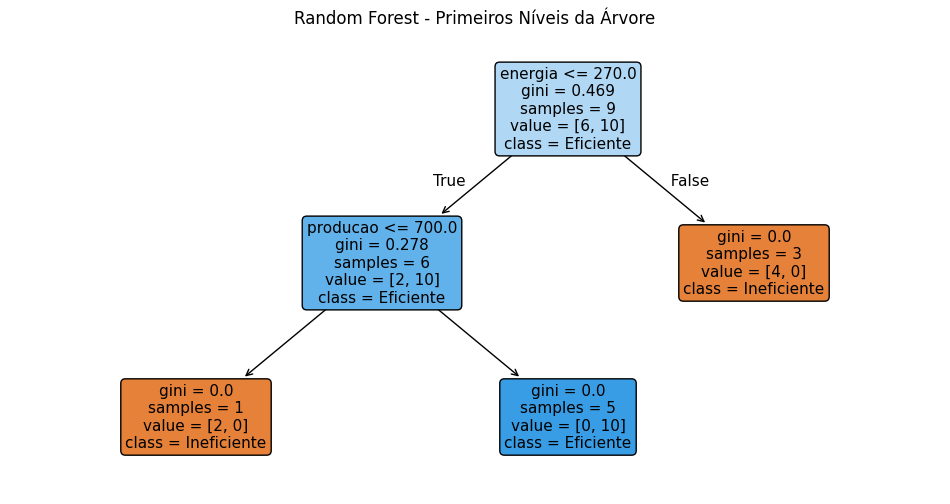

In [ ]:
#13 Visualizar uma árvore do Random Forest
plt.figure(figsize=(12, 6))

plot_tree(
    modelo_rf.estimators_[0],
    feature_names=["producao", "energia"],
    class_names=["Ineficiente", "Eficiente"],
    filled=True,
    rounded=True,
    max_depth=2,  # Mostra somente os primeiros níveis
    fontsize=11
)

plt.title("Random Forest - Primeiros Níveis da Árvore")
plt.show()

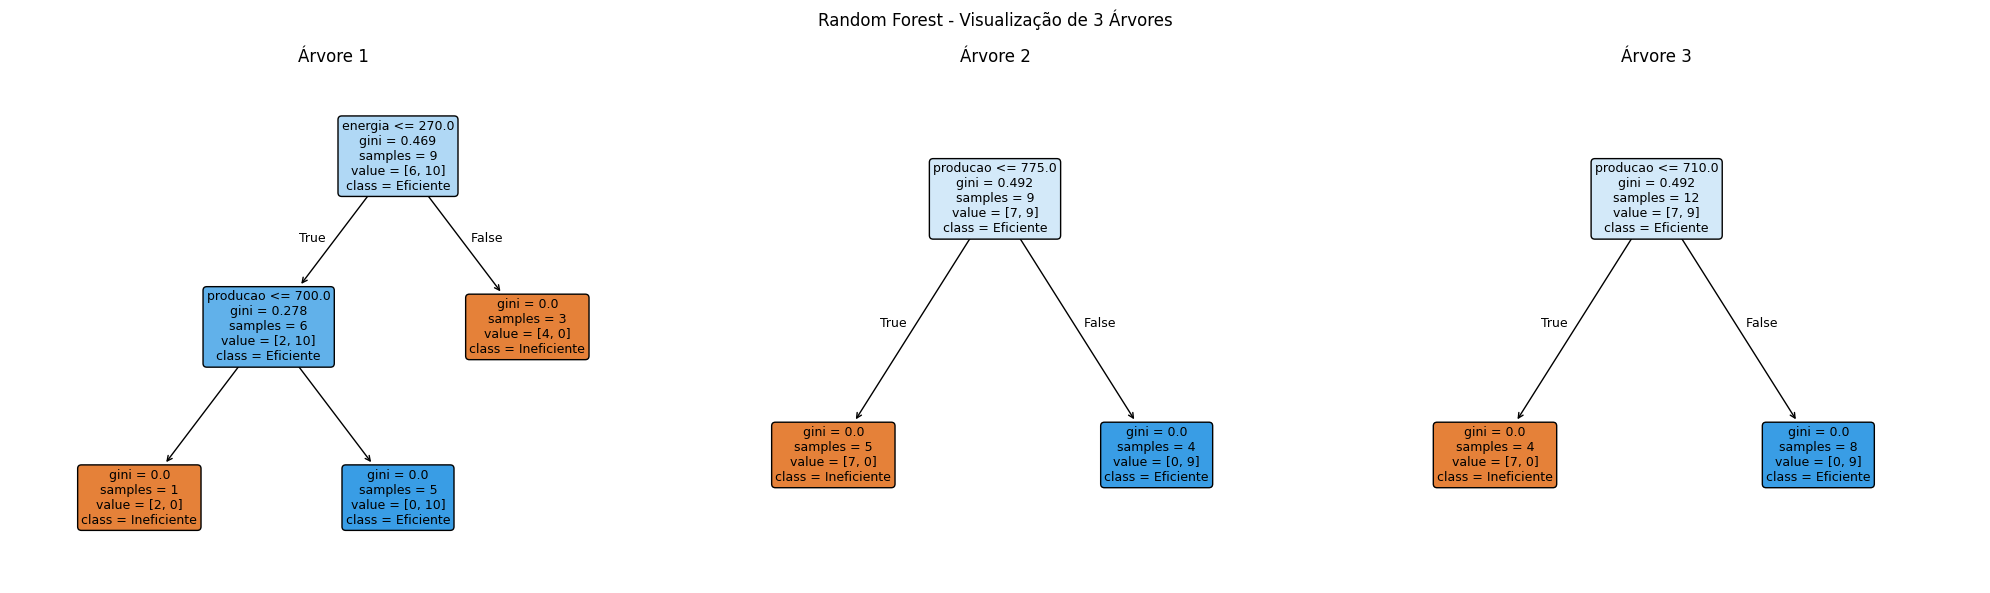

In [ ]:
# 14 Visualizar varias arvores de decisao Random Forest
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
# Cria uma figura com três gráficos
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Percorre as três primeiras árvores
for i in range(3):

    # Seleciona a árvore correspondente
    arvore = modelo_rf.estimators_[i]

    # Plota a árvore
    plot_tree(
        arvore,
        feature_names=["producao", "energia"],
        class_names=["Ineficiente", "Eficiente"],
        filled=True,
        rounded=True,
        fontsize=9,
        ax=axes[i]
    )

    # Define o título de cada árvore
    axes[i].set_title(f"Árvore {i + 1}")

plt.suptitle("Random Forest - Visualização de 3 Árvores")
plt.tight_layout()
plt.show()

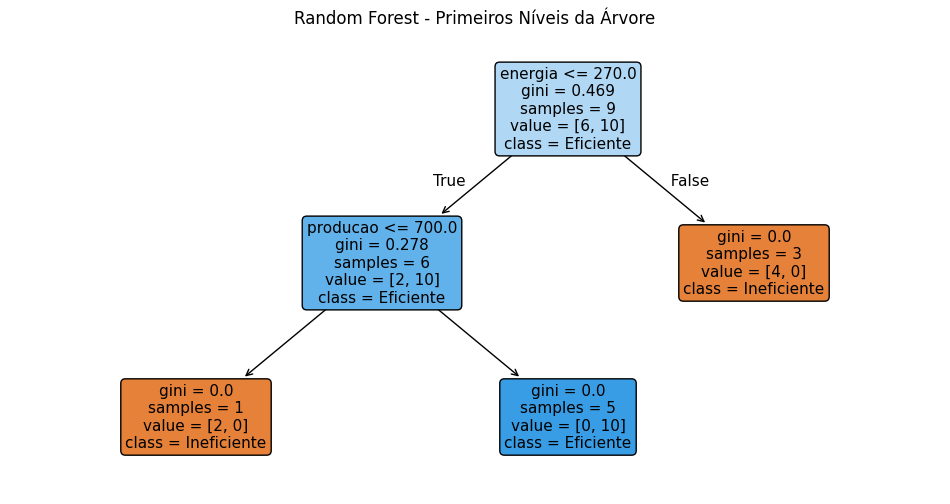

In [ ]:
#15
plt.figure(figsize=(12, 6))

plot_tree(
    modelo_rf.estimators_[0],
    feature_names=["producao", "energia"],
    class_names=["Ineficiente", "Eficiente"],
    filled=True,
    rounded=True,
    max_depth=2,  # Mostra somente os primeiros níveis
    fontsize=11
)

plt.title("Random Forest - Primeiros Níveis da Árvore")
plt.show()